In [1]:
print("ok")

ok


In [2]:
# step download the facial landmarker model from google
import urllib.request
import os

model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/latest/"
    "face_landmarker.task"
)

model_path = "face_landmarker.task"

if not os.path.exists(model_path):
    urllib.request.urlretrieve(model_url, model_path)

print("Face Landmarker model ready!")

Face Landmarker model ready!


In [3]:
# step 2 load the facial landmarker model
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BaseOptions = python.BaseOptions

FaceLandmarker = vision.FaceLandmarker

FaceLandmarkerOptions = vision.FaceLandmarkerOptions

options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True,
    output_facial_transformation_matrixes=True
)

landmarker = FaceLandmarker.create_from_options(options)

print("Face Landmarker initialized!")

Face Landmarker initialized!


In [4]:
# step 3 detect facial landmarks in one frame
video_path = "test_video.mp4"

cap = cv2.VideoCapture(video_path)

success, frame = cap.read()

cap.release()

if not success:
    raise ValueError("Could not read video")

# convert the image to RGB
rgb_frame = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)
# convert the image to mediapipe image object
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)



In [5]:
# now let's detect the facial landmarks
result = landmarker.detect(mp_image)

print("Number of detected faces:", len(result.face_landmarks))

Number of detected faces: 1


In [ ]:
# now that's a face is detected let's inspect it's landmarks
if result.face_landmarks:

    face = result.face_landmarks[0] #this means we are only interested in the first detected face

    print("Total landmarks:", len(face))

    print("First landmark:")
    print(face[0]) #this prints the first landmark which is the left eye

Total landmarks: 478
First landmark:
NormalizedLandmark(x=0.49138975143432617, y=0.6837669610977173, z=-0.0760711058974266, visibility=None, presence=None, name=None)


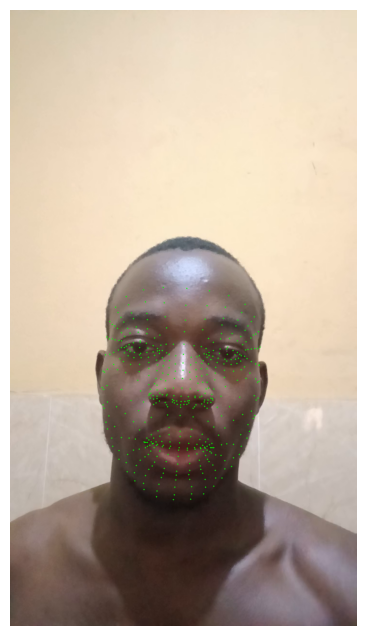

In [7]:
# let's visualize the detected landmarks on the image
if result.face_landmarks:

    face = result.face_landmarks[0]

    height, width = rgb_frame.shape[:2]

    annotated_frame = rgb_frame.copy()

    for landmark in face:

        x = int(landmark.x * width)
        y = int(landmark.y * height)

        cv2.circle(
            annotated_frame,
            (x, y),
            1,
            (0, 255, 0),
            -1
        )

    plt.figure(figsize=(10, 8))

    plt.imshow(annotated_frame)

    plt.axis("off")

    plt.show()

Step 1: Extract mouth landmarks
MediaPipe's face landmark topology gives us specific indices for different facial regions.

##Some useful mouth landmarks include:
###Landmark index	Location
13	Upper inner lip
14	Lower inner lip
78	Left mouth corner
308	Right mouth corner

Let's extract them.

In [8]:
face = result.face_landmarks[0]

upper_lip = face[13]
lower_lip = face[14]

left_mouth = face[78]
right_mouth = face[308]

print("Upper lip:", upper_lip)
print("Lower lip:", lower_lip)

print("Left mouth corner:", left_mouth)
print("Right mouth corner:", right_mouth)

Upper lip: NormalizedLandmark(x=0.48774659633636475, y=0.7106702327728271, z=-0.05655724182724953, visibility=None, presence=None, name=None)
Lower lip: NormalizedLandmark(x=0.48630887269973755, y=0.7144696712493896, z=-0.05875619128346443, visibility=None, presence=None, name=None)
Left mouth corner: NormalizedLandmark(x=0.39598703384399414, y=0.7022510766983032, z=-0.012956244871020317, visibility=None, presence=None, name=None)
Right mouth corner: NormalizedLandmark(x=0.5783301591873169, y=0.710632860660553, z=-0.008622843772172928, visibility=None, presence=None, name=None)


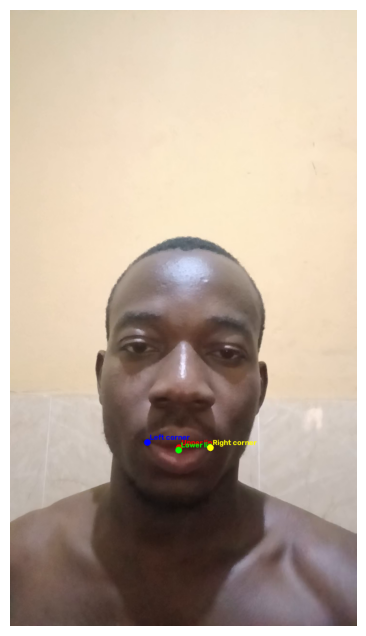

In [9]:
# let's visualize this four points on the image
annotated_frame = rgb_frame.copy()

height, width = rgb_frame.shape[:2]

mouth_points = {
    "Upper lip": (face[13], (255, 0, 0)),
    "Lower lip": (face[14], (0, 255, 0)),
    "Left corner": (face[78], (0, 0, 255)),
    "Right corner": (face[308], (255, 255, 0))
}

for name, (point, color) in mouth_points.items():

    x = int(point.x * width)
    y = int(point.y * height)

    cv2.circle(
        annotated_frame,
        (x, y),
        7,
        color,
        -1
    )

    cv2.putText(
        annotated_frame,
        name,
        (x + 5, y - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        color,
        2
    )

plt.figure(figsize=(10, 8))

plt.imshow(annotated_frame)

plt.axis("off")

plt.show()

In [ ]:
# now let's calculate the distance bewteen upper and lower lip when mouth is open or closed
import numpy as np

height, width = rgb_frame.shape[:2]

upper = np.array([
    face[13].x * width,
    face[13].y * height
])

lower = np.array([
    face[14].x * width,
    face[14].y * height
])

mouth_distance = np.linalg.norm(
    upper - lower
)#It's calculating the Euclidean distance between two points.

print("Mouth opening distance:", mouth_distance)

Mouth opening distance: 4.9722291631176505


In [12]:
#  Instead of looking only at the vertical mouth opening, we can compare it against the mouth's width.


upper = np.array([
    face[13].x * width,
    face[13].y * height
])

lower = np.array([
    face[14].x * width,
    face[14].y * height
])

left = np.array([
    face[78].x * width,
    face[78].y * height
])

right = np.array([
    face[308].x * width,
    face[308].y * height
])

vertical_distance = np.linalg.norm(upper - lower)

horizontal_distance = np.linalg.norm(left - right)

mar = vertical_distance / horizontal_distance

print("Mouth Aspect Ratio:", mar)


Mouth Aspect Ratio: 0.03774713097773061


Facial landmarks for the eyes

In [13]:
# note ear=Eye Aspect Ratio (EAR).
def calculate_ear(face, width, height):

    # Eye landmarks
    left_corner = np.array([
        face[33].x * width,
        face[33].y * height
    ])

    right_corner = np.array([
        face[133].x * width,
        face[133].y * height
    ])

    upper_lid = np.array([
        face[159].x * width,
        face[159].y * height
    ])

    lower_lid = np.array([
        face[145].x * width,
        face[145].y * height
    ])

    vertical = np.linalg.norm(
        upper_lid - lower_lid
    )

    horizontal = np.linalg.norm(
        left_corner - right_corner
    )

    return vertical / horizontal

In [14]:
ear = calculate_ear(
    face,
    width,
    height
)

print("Eye Aspect Ratio:", ear)

Eye Aspect Ratio: 0.30630625600984984
